# Bài tập thực hành 2: EDA tập dữ liệu mua sắm siêu thị (Online Retail)
Dữ liệu: `Online_Retail.xlsx` – giao dịch của cửa hàng bán lẻ tại UK (12/2010 – 12/2011).

## 1. Chuẩn bị dữ liệu

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

df = pd.read_excel('Online_Retail.xlsx')
print(df.shape); print(df.isna().sum())
df.head()

(541909, 8)
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
# Làm sạch: bỏ trùng, hóa đơn hủy (InvoiceNo bắt đầu bằng 'C'), Quantity/UnitPrice <= 0, thiếu Description
df = df.drop_duplicates()
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)].dropna(subset=['Description'])

df['Revenue'] = df['Quantity'] * df['UnitPrice']
df['Month']   = df['InvoiceDate'].dt.to_period('M').astype(str)
df['Weekday'] = df['InvoiceDate'].dt.day_name()
df['Hour']    = df['InvoiceDate'].dt.hour
print(df.shape, '| doanh thu:', round(df['Revenue'].sum()))
df.describe()[['Quantity','UnitPrice','Revenue']]

(524878, 12) | doanh thu: 10642111


,Quantity,UnitPrice,Revenue
count,524878.000000,524878.000000,524878.000000
mean,10.616600,3.922573,20.275399
min,1.000000,0.001000,0.001000
25%,1.000000,1.250000,3.900000
50%,4.000000,2.080000,9.920000
75%,11.000000,4.130000,17.700000
max,80995.000000,13541.330000,168469.600000
std,156.280031,36.093028,271.693566


## 2. Phân tích theo quốc gia và sản phẩm

/tmp/ipykernel_319/3445796307.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_c.values, y=top_c.index, ax=ax[0], palette='Blues_r')
/tmp/ipykernel_319/3445796307.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_p.values, y=top_p.index, ax=ax[1], palette='Greens_r')


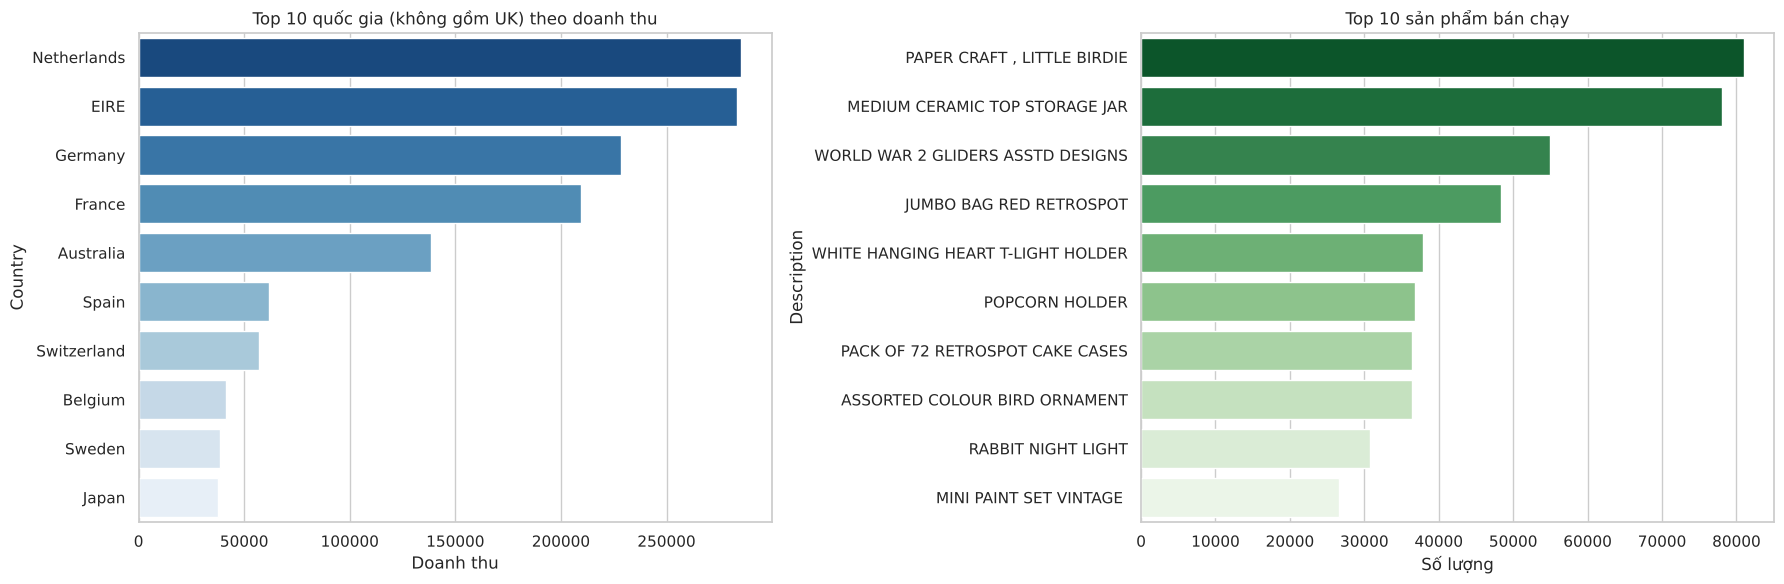

UK chiếm 84.6% doanh thu


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(18,6))
# Top 10 quốc gia theo doanh thu (bỏ UK vì chiếm áp đảo)
top_c = df[df['Country']!='United Kingdom'].groupby('Country')['Revenue'].sum().nlargest(10)
sns.barplot(x=top_c.values, y=top_c.index, ax=ax[0], palette='Blues_r')
ax[0].set_title('Top 10 quốc gia (không gồm UK) theo doanh thu'); ax[0].set_xlabel('Doanh thu')
# Top 10 sản phẩm bán chạy theo số lượng
top_p = df.groupby('Description')['Quantity'].sum().nlargest(10)
sns.barplot(x=top_p.values, y=top_p.index, ax=ax[1], palette='Greens_r')
ax[1].set_title('Top 10 sản phẩm bán chạy'); ax[1].set_xlabel('Số lượng')
plt.tight_layout(); plt.show()
print('UK chiếm %.1f%% doanh thu' % (100*df[df.Country=='United Kingdom'].Revenue.sum()/df.Revenue.sum()))

## 3. Phân tích theo thời gian

/tmp/ipykernel_319/45817835.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df.drop_duplicates('InvoiceNo'), x='Weekday', order=order, ax=ax[1], palette='viridis')
/tmp/ipykernel_319/45817835.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df.drop_duplicates('InvoiceNo'), x='Hour', ax=ax[2], palette='magma')


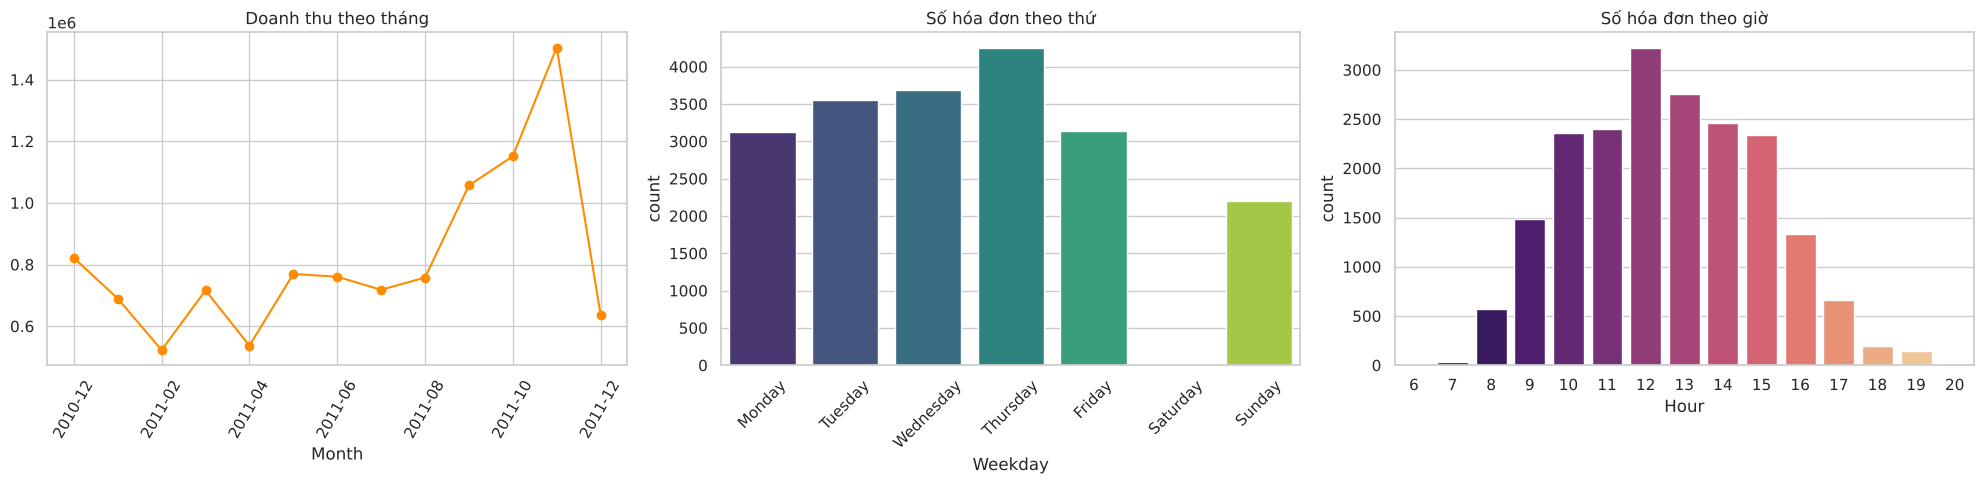

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(20,5))
df.groupby('Month')['Revenue'].sum().plot(marker='o', ax=ax[0], color='darkorange')
ax[0].set_title('Doanh thu theo tháng'); ax[0].tick_params(axis='x', rotation=60)
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
sns.countplot(data=df.drop_duplicates('InvoiceNo'), x='Weekday', order=order, ax=ax[1], palette='viridis')
ax[1].set_title('Số hóa đơn theo thứ'); ax[1].tick_params(axis='x', rotation=45)
sns.countplot(data=df.drop_duplicates('InvoiceNo'), x='Hour', ax=ax[2], palette='magma')
ax[2].set_title('Số hóa đơn theo giờ')
plt.tight_layout(); plt.show()

## 4. Phân tích khách hàng và phân phối

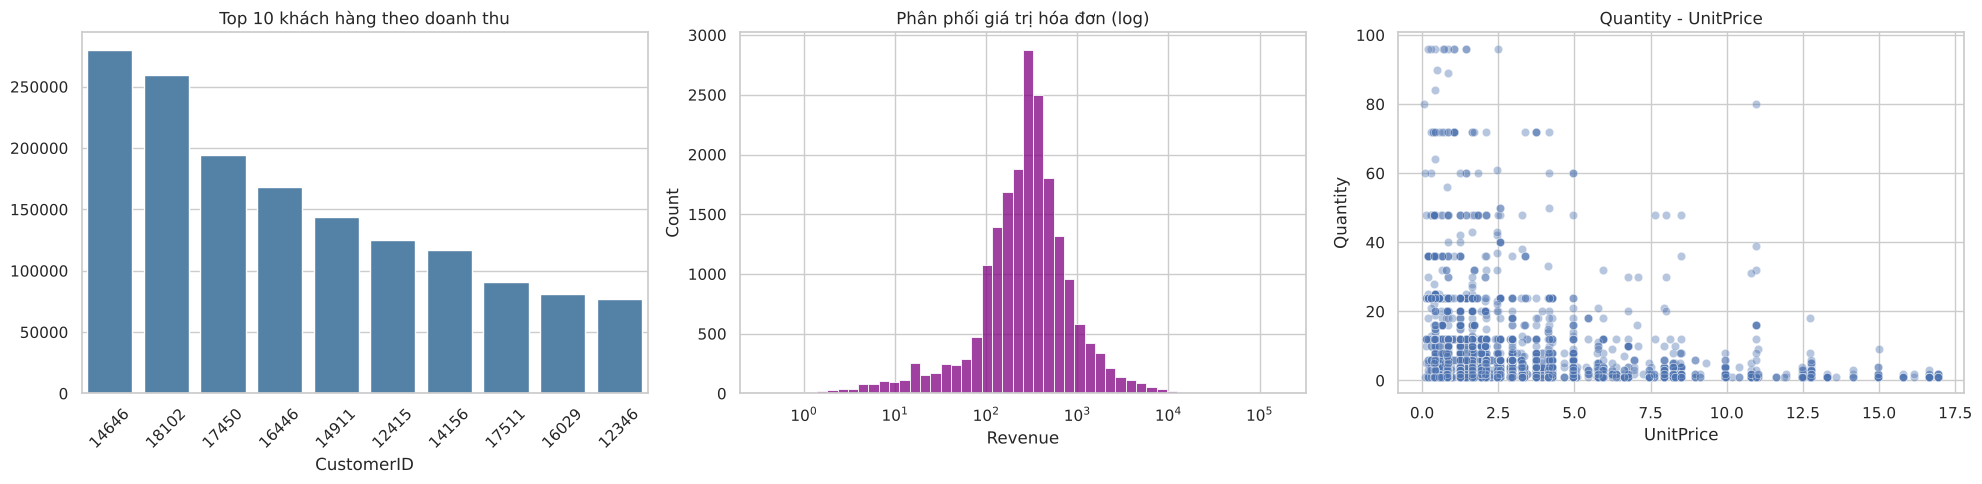

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(20,5))
# Top 10 khách hàng
cust = df.groupby('CustomerID')['Revenue'].sum().nlargest(10)
sns.barplot(x=cust.index.astype(int).astype(str), y=cust.values, ax=ax[0], color='steelblue')
ax[0].set_title('Top 10 khách hàng theo doanh thu'); ax[0].tick_params(axis='x', rotation=45)
# Phân phối giá trị mỗi hóa đơn (log)
inv = df.groupby('InvoiceNo')['Revenue'].sum()
sns.histplot(inv, bins=50, log_scale=True, ax=ax[1], color='purple')
ax[1].set_title('Phân phối giá trị hóa đơn (log)')
# Quantity vs UnitPrice (cắt ngoại lệ ở phân vị 99)
s = df[(df.Quantity < df.Quantity.quantile(.99)) & (df.UnitPrice < df.UnitPrice.quantile(.99))].sample(5000, random_state=1)
sns.scatterplot(data=s, x='UnitPrice', y='Quantity', alpha=.4, ax=ax[2])
ax[2].set_title('Quantity - UnitPrice')
plt.tight_layout(); plt.savefig('retail_eda.png', dpi=150); plt.show()

## 5. Kết luận
- Vương quốc Anh chiếm phần lớn doanh thu; các thị trường xuất khẩu chính tiếp theo là Hà Lan, EIRE, Đức, Pháp.
- Doanh thu tăng mạnh vào quý 4 (Sep–Nov), đạt đỉnh tháng 11 (~1,5 triệu) do mùa mua sắm cuối năm.
- Giao dịch tập trung vào ngày trong tuần, cao điểm 10h–15h (đỉnh lúc 12h), thứ Năm nhiều nhất và không có giao dịch vào thứ Bảy.
- Giá trị hóa đơn và số lượng mua lệch phải mạnh (ít đơn rất lớn), một nhóm nhỏ khách hàng đóng góp doanh thu lớn.